<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A higher canopy statistic does not imply growth

What changes when we require a closer ground return before estimating a tree's height? We will hold a classified point cloud fixed, tighten that support radius, and watch the population behind a height percentile change. A separate conductor-clearance calculation provides a control: it measures absolute 3D distance and does not normalize to ground.

**This is a constructed scientific fixture, not a surveyed site.** The pinned worker packages `classified.laz`, a 29-return cloud with 25 flat-ground returns, two building returns and two vegetation returns, plus a site polygon and a 3D conductor. There are no observation dates, live services or external credentials. The real LAS/LAZ, nearest-ground and segment-distance implementation executes through VGI; no result is fabricated if it fails.

## Choose how close ground support must be

`GROUND_RADIUS_M` is a positive horizontal distance in metres. Default **25 m** accepts nearby class-2 ground support; the separate experiment uses **2 m**. The comparison always retains a fixed 25 m reference. Building and vegetation heights are point Z minus the nearest usable ground return's Z, only when that return is within the inclusive radius.

Inputs use **EPSG:32618**, X/Y order in metres. Cloud and conductor Z share a synthetic absolute-metre datum: ground is 100 m and the conductor is 120 m. XY reprojection does not convert vertical datums. We fix the 5 m grid, 2 m canopy-height cutoff and a 3 m illustrative clearance screen. Restart Kernel → Run All after editing.

In [1]:
GROUND_RADIUS_M = 25.0  # metres, >0; experiment: 2.0

In [2]:
import hashlib
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(GROUND_RADIUS_M, (int, float)) and not isinstance(GROUND_RADIUS_M, bool)
assert np.isfinite(GROUND_RADIUS_M) and GROUND_RADIUS_M > 0
sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Synthetic bundled LAZ · EPSG:32618 / metres · selected ground radius {GROUND_RADIUS_M:g} m",
        fontsize=8,
        color="#555555",
    )
    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.20, top=0.80, wspace=0.27)
    plt.show()


secret_directory = TemporaryDirectory(prefix="lidar-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
Path("artifacts").mkdir(exist_ok=True)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-lidar/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-lidar/notebooks/pyproject.toml.

## Keep heights and clearance as separate measurements

The literal command below fetches an immutable public Git revision with locked worker constraints. `demo://classified.laz` resolves inside that installed package. No parent checkout is needed.

Three deliberate analysis calls materialize reference heights, selected heights and a fixed **12 m** conductor-distance envelope. Both vegetation returns fall inside that envelope. Later SQL applies the illustrative **3 m** screen locally. `max_points` bounds the entire loaded tile; `max_grid_cells`, segment count and candidate-distance caps reject excessive work rather than silently truncating it. These are computational bounds, not SQL row limits.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'lidar' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-lidar.git@7d25870f8d6e6afec091fdf75a7bf602eb88a0de --constraints worker-constraints.txt vgi-lidar-worker');
CREATE TABLE site AS SELECT * FROM lidar.demo_input();
CREATE TABLE conductor AS SELECT * FROM lidar.demo_input(kind := 'conductor');
CREATE TABLE reference_metrics AS
SELECT * FROM lidar.height_metrics((SELECT * FROM site),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 ground_radius_m := 25.0, grid_size_m := 5.0, canopy_height_m := 2.0,
 max_points := 100, max_grid_cells := 100);
CREATE TABLE selected_metrics AS
SELECT * FROM lidar.height_metrics((SELECT * FROM site),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 ground_radius_m := {{GROUND_RADIUS_M}}, grid_size_m := 5.0, canopy_height_m := 2.0,
 max_points := 100, max_grid_cells := 100);
CREATE TABLE clearance_envelope AS
SELECT * FROM lidar.vegetation_clearance((SELECT * FROM conductor),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 clearance_m := 12.0, max_points := 100, max_segments := 10,
 max_distance_evaluations := 100);

,Count


## Reconcile the population before comparing the percentile

A polygon with returns can still lack support for some building or vegetation heights. Those returns are counted in `unsupported_points` and excluded from height percentiles. A higher percentile after exclusion can be a population effect.

The site is a 50 × 50 m square with 100 intersecting 5 × 5 m cells. Only observed cells participate in the support calculation; only observed cells with **every contained point ground-supported** participate in canopy cover. SQL reconstructs the corresponding integer denominators for this exact fixture. The resulting cover fraction is not wall-to-wall canopy area.

In [4]:
%%sql
CREATE TABLE comparison AS
WITH scenarios AS (
 SELECT 'Reference · 25 m' scenario,* FROM reference_metrics
 UNION ALL SELECT 'Selected' scenario,* FROM selected_metrics)
SELECT *,round(100*observed_cell_fraction)::INTEGER observed_cells,
 round(100*observed_cell_fraction*ground_supported_cell_fraction)::INTEGER supported_cells,
 round(100*observed_cell_fraction*ground_supported_cell_fraction*canopy_cover_fraction)::INTEGER canopy_cells
FROM scenarios;

,Count


In [5]:
%%sql metrics <<
SELECT scenario,point_count,building_points,building_p95_m,building_max_m,
 vegetation_points,canopy_p95_m,canopy_max_m,unsupported_points,status,
 observed_cells,supported_cells,canopy_cells,canopy_cover_fraction
FROM comparison ORDER BY scenario;

In [6]:
%%sql checks <<
SELECT
 (SELECT count(*)-count(DISTINCT feature_id) FROM selected_metrics) duplicate_keys,
 (SELECT count(*) FROM selected_metrics s JOIN reference_metrics r USING(feature_id)
  WHERE s.point_count<>r.point_count OR s.observed_cell_fraction<>r.observed_cell_fraction) changed_observations,
 count(*) FILTER(WHERE building_points+vegetation_points+unsupported_points<>4) population_mismatches,
 count(*) FILTER(WHERE building_p95_m>building_max_m OR canopy_p95_m>canopy_max_m) percentile_mismatches,
 count(*) FILTER(WHERE observed_cells<>26 OR supported_cells>observed_cells OR canopy_cells>supported_cells) cell_mismatches,
 count(*) FILTER(WHERE abs(canopy_cover_fraction-canopy_cells::DOUBLE/supported_cells)>1e-12) fraction_mismatches,
 count(*) FILTER(WHERE (building_points=0)<>(building_p95_m IS NULL)
  OR (vegetation_points=0)<>(canopy_p95_m IS NULL)) missing_height_mismatches,
 count(*) FILTER(WHERE status<>CASE WHEN unsupported_points>0 THEN 'partial_ground' ELSE 'ok' END) status_mismatches,
 (SELECT count(*) FROM clearance_envelope
  WHERE abs(clearance_m-sqrt(pow(x-nearest_x,2)+pow(y-nearest_y,2)+pow(z_m-nearest_z_m,2)))>1e-12
   OR clearance_m>12 OR cloud_crs<>'EPSG:32618') distance_mismatches
FROM comparison;

In [7]:
display(checks)
assert checks.iloc[0].eq(0).all()
assert con.execute("SELECT count(*) FROM clearance_envelope").fetchone()[0] == 2
assert con.execute("SELECT count(*) FROM comparison WHERE cloud_crs<>'EPSG:32618'").fetchone()[0] == 0
reference = con.execute("SELECT * FROM reference_metrics ORDER BY feature_id").df()
clearance = con.execute("SELECT * FROM clearance_envelope ORDER BY point_index").df()
fingerprint = hashlib.sha256(
    (reference.to_json(orient="records") + clearance.to_json(orient="records")).encode()
).hexdigest()
prose(
    f"Nine SQL consistency checks and the CRS/population controls pass. Reference metrics plus the fixed clearance envelope have fingerprint `{fingerprint}`; changing ground support must leave that control unchanged. These checks establish behavior on a known fixture, not survey accuracy."
)

,duplicate_keys,changed_observations,population_mismatches,percentile_mismatches,cell_mismatches,fraction_mismatches,missing_height_mismatches,status_mismatches,distance_mismatches
0,0,0,0,0,0,0,0,0,0


Nine SQL consistency checks and the CRS/population controls pass. Reference metrics plus the fixed clearance envelope have fingerprint `962635dd242f3a806dac19989fd3f5e522f7c8286fced08f7a7b3d5e3c271c6a`; changing ground support must leave that control unchanged. These checks establish behavior on a known fixture, not survey accuracy.

,scenario,point_count,building_points,building_p95_m,building_max_m,vegetation_points,canopy_p95_m,canopy_max_m,unsupported_points,status,observed_cells,supported_cells,canopy_cells,canopy_cover_fraction
0,Reference · 25 m,29,2,11.9,12.0,2,17.6,18.0,0,ok,26,26,2,0.076923
1,Selected,29,2,11.9,12.0,2,17.6,18.0,0,ok,26,26,2,0.076923


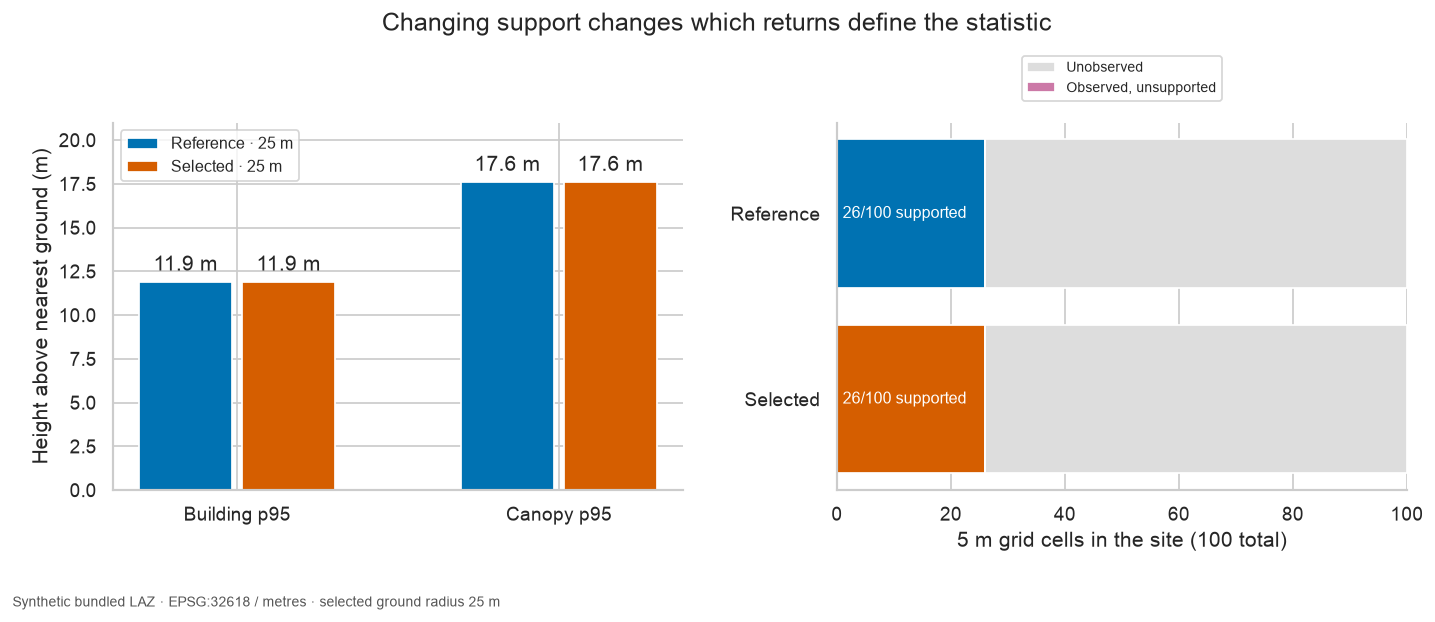

At **25 m**, the selected canopy p95 is **17.6 m**, versus **17.6 m** in the reference. Supported vegetation returns are **2 versus 2**; unsupported building/vegetation returns are **0**. Both still observe **26/100 cells**. Canopy cover is **2/26 = 7.7%** of supported observed cells, not 7.7% of the entire site.

In [8]:
display(metrics)
ref = metrics.iloc[0]
sel = metrics.iloc[1]
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.9))
x = np.arange(2)
for offset, row, color, label in [
    (-0.16, ref, "#0072b2", "Reference · 25 m"),
    (0.16, sel, "#d55e00", f"Selected · {GROUND_RADIUS_M:g} m"),
]:
    bars = a.bar(x + offset, [row.building_p95_m, row.canopy_p95_m], width=0.29, color=color, label=label)
    a.bar_label(bars, fmt="%.1f m", padding=4)
a.set(
    xticks=x,
    xticklabels=["Building p95", "Canopy p95"],
    ylim=(0, 21),
    ylabel="Height above nearest ground (m)",
)
a.legend(fontsize=9, loc="upper left")
y = np.arange(2)
b.barh(y, [ref.supported_cells, sel.supported_cells], color=["#0072b2", "#d55e00"])
b.barh(
    y,
    [100 - ref.observed_cells, 100 - sel.observed_cells],
    left=[ref.observed_cells, sel.observed_cells],
    color="#dddddd",
    label="Unobserved",
)
b.barh(
    y,
    [ref.observed_cells - ref.supported_cells, sel.observed_cells - sel.supported_cells],
    left=[ref.supported_cells, sel.supported_cells],
    color="#cc79a7",
    label="Observed, unsupported",
)
for i, row in enumerate([ref, sel]):
    b.text(1, i, f"{row.supported_cells}/100 supported", va="center", color="white", fontsize=9)
b.set(
    yticks=y,
    yticklabels=["Reference", "Selected"],
    xlim=(0, 100),
    xlabel="5 m grid cells in the site (100 total)",
)
b.invert_yaxis()
b.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.20))
fig.suptitle("Changing support changes which returns define the statistic")
finish(fig)
prose(
    f"At **{GROUND_RADIUS_M:g} m**, the selected canopy p95 is **{sel.canopy_p95_m:.1f} m**, versus **{ref.canopy_p95_m:.1f} m** in the reference. Supported vegetation returns are **{sel.vegetation_points} versus {ref.vegetation_points}**; unsupported building/vegetation returns are **{sel.unsupported_points}**. Both still observe **{sel.observed_cells}/100 cells**. Canopy cover is **{sel.canopy_cells}/{sel.supported_cells} = {sel.canopy_cover_fraction:.1%}** of supported observed cells, not {sel.canopy_cover_fraction:.1%} of the entire site."
)

## Absolute clearance does not need a ground estimate

The worker measures the shortest Euclidean 3D distance from each vegetation return to the supplied conductor segments. This is a different quantity from height above ground. Here the line is horizontal at 120 m, both closest points lie directly above their returns, and the distance reduces to a vertical difference. The SQL reconstruction checks all three coordinate differences, so it does not assume that simplification for general conductors.

The fixed 12 m envelope supplies both returns for this view; the 3 m screen is just a local analytical choice. Neither its threshold nor an absence of selected returns establishes regulatory compliance, safety or complete vegetation detection.

In [9]:
%%sql distances <<
SELECT point_index,x-500000 AS local_easting_m,z_m,nearest_z_m,clearance_m,
 clearance_m<=3.0 AS inside_illustrative_screen
FROM clearance_envelope ORDER BY point_index;

,point_index,local_easting_m,z_m,nearest_z_m,clearance_m,inside_illustrative_screen
0,27,30.0,118.0,120.0,2.0,True
1,28,35.0,110.0,120.0,10.0,False


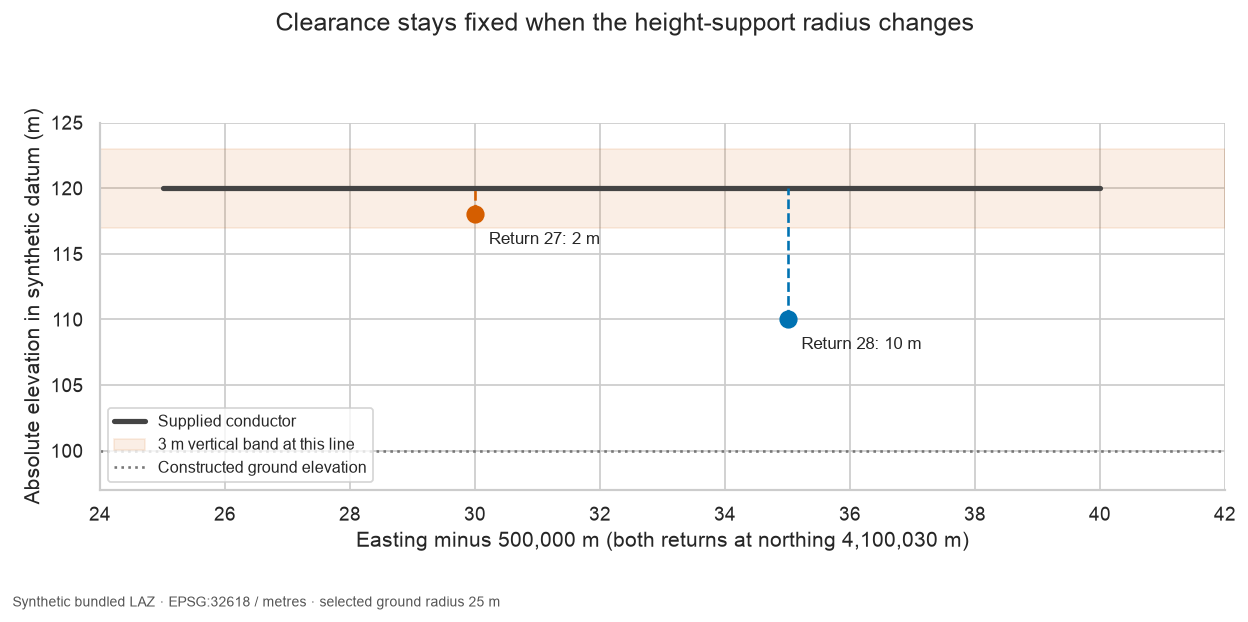

The 12 m envelope contains **2 vegetation returns**. **1** meets the illustrative 3 m screen; the nearest distance is **2 m**. These coordinates and distances are unchanged by `GROUND_RADIUS_M`. Tightening support can change the canopy summary while leaving this separate absolute-distance calculation intact.

In [10]:
display(distances)
fig, ax = plt.subplots(figsize=(10, 4.9))
ax.plot([25, 40], [120, 120], color="#444444", linewidth=3, label="Supplied conductor")
ax.axhspan(117, 123, color="#d55e00", alpha=0.10, label="3 m vertical band at this line")
for row in distances.itertuples():
    color = "#d55e00" if row.inside_illustrative_screen else "#0072b2"
    ax.plot([row.local_easting_m] * 2, [row.z_m, row.nearest_z_m], color=color, linestyle="--")
    ax.scatter(row.local_easting_m, row.z_m, s=90, color=color, zorder=5)
    ax.annotate(
        f"Return {row.point_index}: {row.clearance_m:g} m",
        (row.local_easting_m, row.z_m),
        xytext=(8, -17),
        textcoords="offset points",
        fontsize=10,
    )
ax.axhline(100, color="#777777", linestyle=":", label="Constructed ground elevation")
ax.set(
    xlim=(24, 42),
    ylim=(97, 125),
    xlabel="Easting minus 500,000 m (both returns at northing 4,100,030 m)",
    ylabel="Absolute elevation in synthetic datum (m)",
)
ax.legend(loc="lower left", fontsize=9)
fig.suptitle("Clearance stays fixed when the height-support radius changes")
finish(fig)
selected = int(distances.inside_illustrative_screen.sum())
prose(
    f"The 12 m envelope contains **{len(distances)} vegetation returns**. **{selected}** meets the illustrative 3 m screen; the nearest distance is **{distances.clearance_m.min():g} m**. These coordinates and distances are unchanged by `GROUND_RADIUS_M`. Tightening support can change the canopy summary while leaving this separate absolute-distance calculation intact."
)

## Carry the denominator and datum into the next analysis

For a real classified tile, retain ground support, point counts, grid coverage and NULL/status fields alongside height percentiles. A percentile based on a changed population is not evidence of tree growth. Nearest-ground normalization may be unsuitable on steep terrain or with sparse/misclassified ground; a supported estimate is not a guarantee of accuracy.

The worker excludes noise classes 7/18 and withheld returns, uses vegetation classes 3/4/5 and building class 6, and performs no classification or conductor extraction. Clearance depends on supplied conductor geometry, positioning and a common vertical datum. Sparse samples cannot certify an empty or safe corridor.

**Try the separate 2 m experiment:** expect the lower vegetation return to lose ground support, canopy p95 to rise, and the unchanged clearance control to retain both distances. The README gives an output-isolated command, so the saved default remains reviewable.

In [11]:
audit = {
    "ground_radius_m": GROUND_RADIUS_M,
    "control_fingerprint": fingerprint,
    "reference": json.loads(reference.to_json(orient="records")),
    "metrics": json.loads(metrics.to_json(orient="records")),
    "clearance": json.loads(clearance.to_json(orient="records")),
    "checks": checks.iloc[0].to_dict(),
}
Path("artifacts/analysis-audit.json").write_text(json.dumps(audit, indent=2) + "\n")
con.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)